In [4]:
import os
import json
import argparse
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d


def read_file(file_path):
    data = []
    with open(file_path, 'r') as file:
        next(file)  # ignore the first line
        for line in file:
            parts = line.split()
            row = list(map(float, parts))
            data.append(row)
    return data


def get_greedy_BPP(x_values, y_values):
    # Sort data by y_values while keeping x_values in corresponding order
    sorted_pairs = sorted(zip(y_values, x_values, range(len(y_values))), key=lambda x: x[0], reverse=True)
    sorted_y_values, sorted_x_values, sorted_index = zip(*sorted_pairs)  # Unzip pairs into separate lists

    best_y = sorted_y_values[0]
    best_x = sorted_x_values[0]
    print("Best accuracy: {y:.8f} at epoch: {index:.0f} with BPP: {x:.8f}".format(y=best_y, index=sorted_index[0], x=best_x))
    
    new_y = []
    new_x = []
    new_index = []
    for index, y_value in enumerate(sorted_y_values):
        if sorted_x_values[index] <= best_x and y_value <= best_y:
            best_x = sorted_x_values[index]
            best_y = y_value
            new_y.append(y_value)
            new_x.append(sorted_x_values[index])
            new_index.append(sorted_index[index])
    
    return new_x, new_y, new_index


def get_greedy_Entropy(x_values, y_values):
    # Sort data by y_values while keeping x_values in corresponding order
    sorted_pairs = sorted(zip(y_values, x_values, range(len(y_values))), key=lambda x: x[0], reverse=True)
    sorted_y_values, sorted_x_values, sorted_index = zip(*sorted_pairs)  # Unzip pairs into separate lists

    best_y = sorted_y_values[0]
    best_x = sorted_x_values[0]
    print("Best accuracy: {y:.8f} at epoch: {index:.0f} with Entropy: {x:.8f}".format(y=best_y, index=sorted_index[0]+1, x=best_x))
    
    new_y = []
    new_x = []
    new_index = []
    for index, y_value in enumerate(sorted_y_values):
        if sorted_x_values[index] <= best_x and y_value <= best_y:
            best_x = sorted_x_values[index]
            best_y = y_value
            new_y.append(y_value)
            new_x.append(sorted_x_values[index])
            new_index.append(sorted_index[index])
    
    return new_x, new_y, new_index


def plot_data_bpp(file_path, marker, label, color, greedy=True):
    data = read_file(file_path)
    print("len of \'", label, "\' data:", len(data), end="\t")
    
    y_values = [row[2] for row in data] # test acc
    # x_values = [269.63494 / (row[7] + row[8] + row[9] + row[10]) for row in data] # CR
    x_values = [(row[6]) for row in data] # test bpp
    
    if len(x_values) > 100:
        y_values = y_values[:100]
        x_values = x_values[:100]
    # x_values = [row[4] for row in data] # test loss

    if greedy:
        new_x_values, new_y_values, new_index = get_greedy_BPP(x_values, y_values)
        plt.plot(x_values, y_values, marker=marker, color=color, alpha=0.2, linestyle="")
        plt.plot(new_x_values, new_y_values, marker=marker, label=label, color=color, alpha=1)
        for i, (x, y) in enumerate(zip(new_x_values, new_y_values)):
            plt.annotate(str(new_index[i]), (x, y), textcoords="offset points", xytext=(0,6), ha='center', color=color, fontsize=8)
        return new_index[0]
    else:
        # plt.plot(x_values, y_values, marker=marker, label=label, color=color, alpha=0.9, linestyle="")
        plt.plot(x_values, y_values, marker=marker, label=label, color=color, alpha=0.9)
        for i, (x, y) in enumerate(zip(x_values, y_values)):
            plt.annotate(str(i), (x, y), textcoords="offset points", xytext=(0,6), ha='center', color=color, fontsize=8)
        return -1


def plot_data_entropy(file_path, marker, label, color, greedy=True):
    data = read_file(file_path)
    y_values = [row[2] for row in data] # test acc
    x_values = [(row[7] + row[8] + row[9] + row[10]) for row in data] # entropy
    # x_values = [24 / (row[6]) for row in data] # bpp
    
    if len(x_values) > 100:
        y_values = y_values[:100]
        x_values = x_values[:100]
    # x_values = [row[4] for row in data] # test loss

    if greedy:
        new_x_values, new_y_values, new_index = get_greedy_Entropy(x_values, y_values)
        plt.plot(x_values, y_values, marker=marker, color=color, alpha=0.2, linestyle="")
        plt.plot(new_x_values, new_y_values, marker=marker, label=label, color=color, alpha=1)
        for i, (x, y) in enumerate(zip(new_x_values, new_y_values)):
            plt.annotate(str(new_index[i]), (x, y), textcoords="offset points", xytext=(0,10), ha='center', color=color, fontsize=8)
        return new_index[0]+1
    else:
        # plt.plot(x_values, y_values, marker=marker, label=label, color=color, alpha=0.9, linestyle="")
        plt.plot(x_values, y_values, marker=marker, label=label, color=color, alpha=0.9)
        for i, (x, y) in enumerate(zip(x_values, y_values)):
            plt.annotate(str(i), (x, y), textcoords="offset points", xytext=(0,10), ha='center', color=color, fontsize=8)
        return -1


def plot_data_HDQ(base_path='./save/imagenet/resnet18', lower=1, upper=100):
    HDQ_file = os.path.join(base_path,"HDQ.txt")
    data = read_file(HDQ_file)
    # plot baseline for HDQ
    QF_ls = [int(row[0]) for row in data]
    HDQ_y = [row[1] for row in data]
    HDQ_x = [row[2] for row in data]
    
    sorted_lists = [(qf, y, x) for qf, y, x in sorted(zip(QF_ls, HDQ_y, HDQ_x)) if lower <= qf <= upper]

    QF_ls, HDQ_y, HDQ_x = map(list, zip(*sorted_lists))
    
    plt.plot(HDQ_x, HDQ_y, marker="x", label="HDQ", color='k', alpha=0.7)
    for i, (x, y) in enumerate(zip(HDQ_x, HDQ_y)):
        if QF_ls[i] % 10 == 0:
            plt.annotate(str(QF_ls[i]), (x, y), textcoords="offset points", xytext=(5,-7), ha='center', fontsize=8)

    return HDQ_x, HDQ_y


color_list = ['r','g','b','m','y','#cf717f','#1f7f7f','#e377c2','#caada2','#ddd7c2']
marker_list = ['o','^','.','v','>','v','|','_',',','+','x']

# base_path = './save/imagenet/resnet18'
base_path = './save/imagenet/mobilenet_v2'
# base_path = './save/imagenet/ConvNeXt_tiny'

# Greedy across all experiments

len(data): 434
len(labels) 434


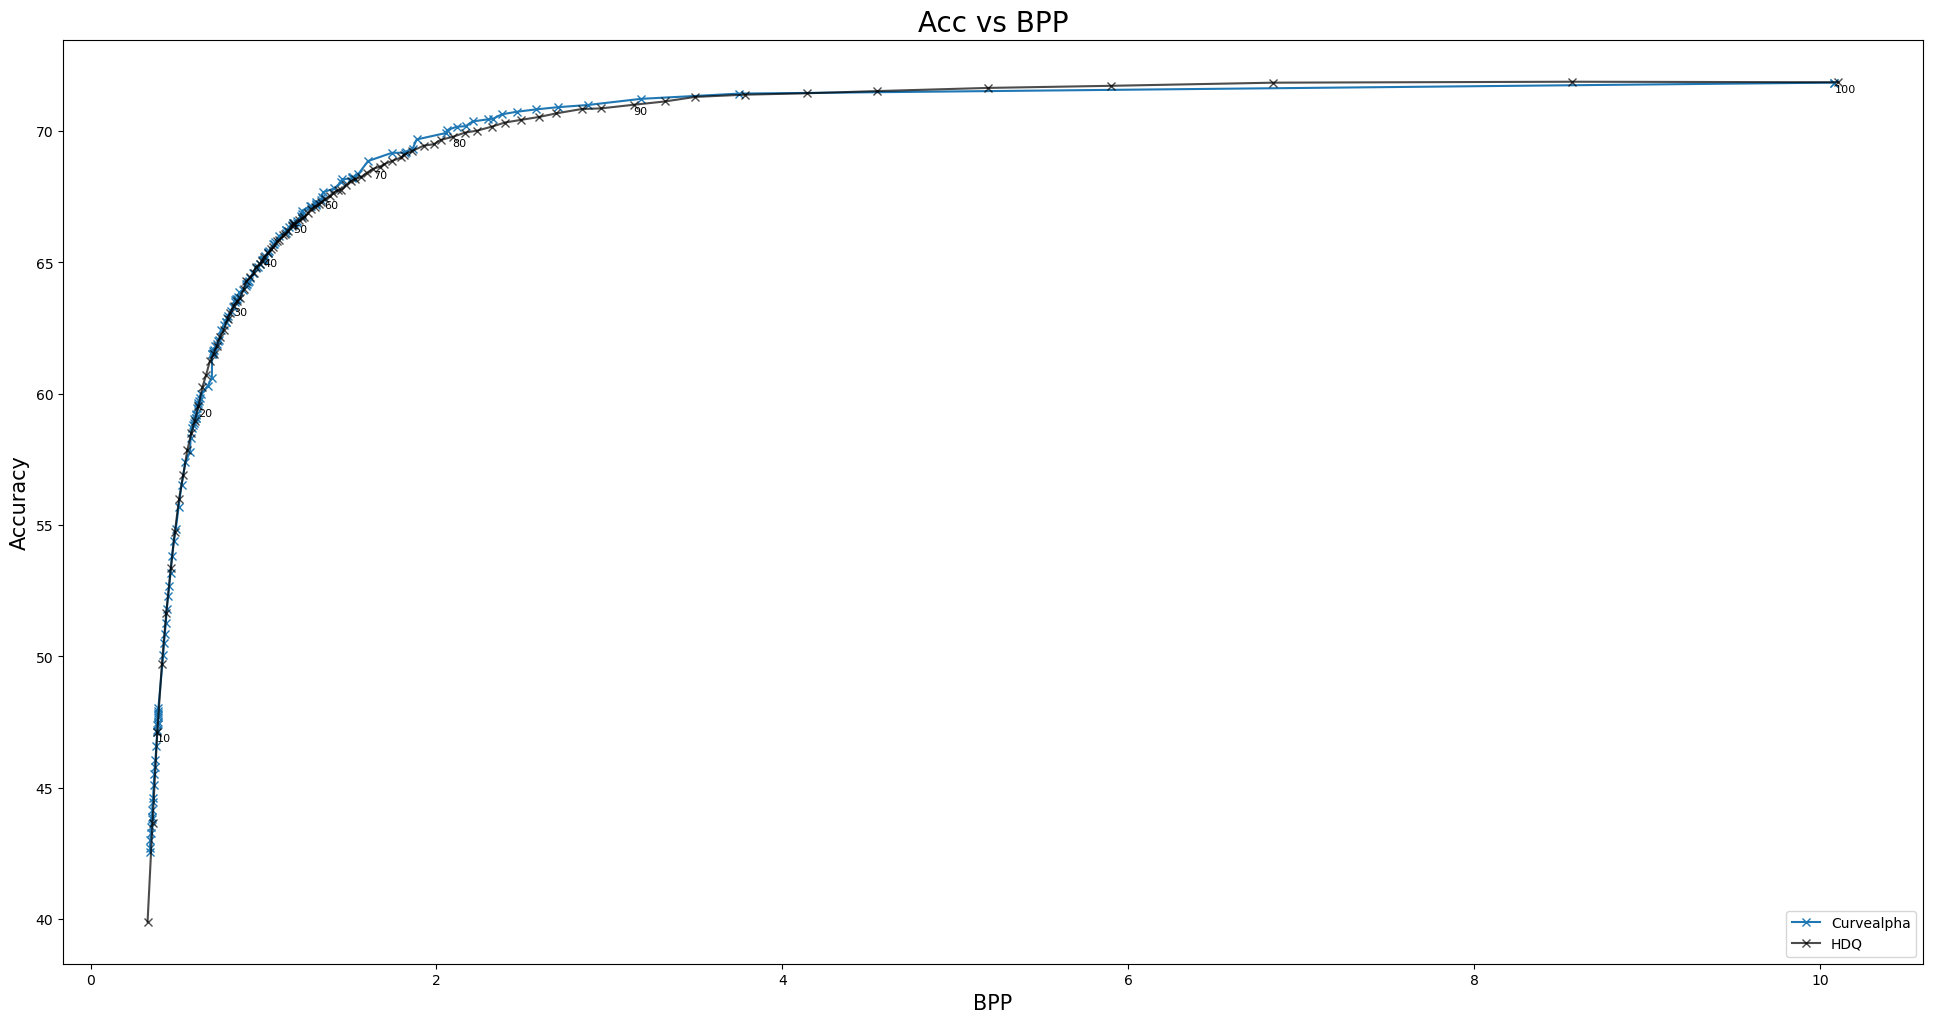

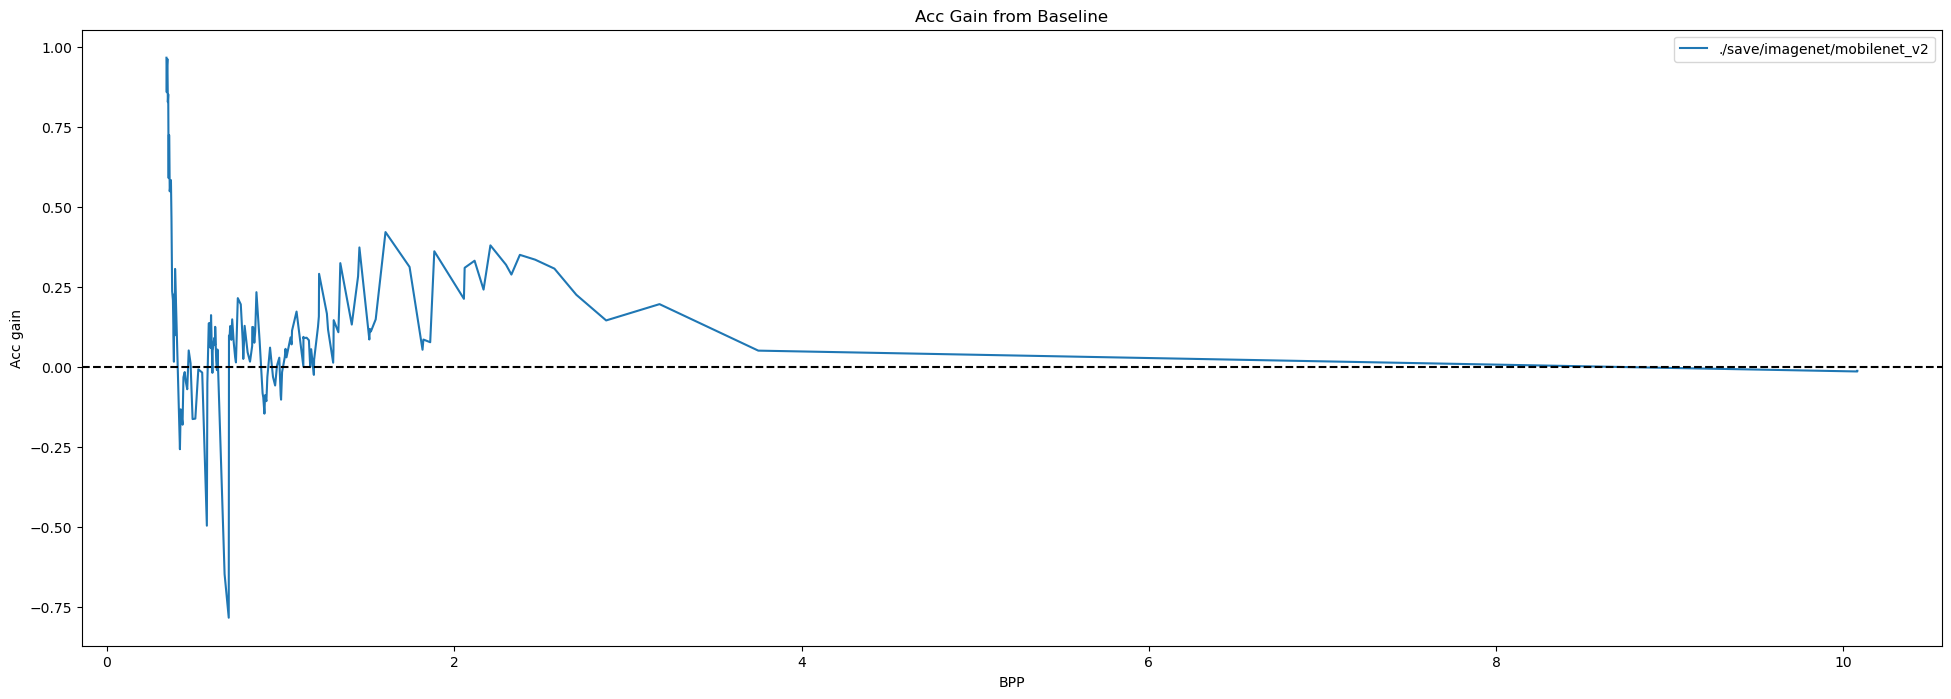

In [26]:

def load_all_log_files(directory, text_filter=""):
    all_data = []
    labels = []
    count = 0
    for dir_name in os.listdir(directory):
        dir_path = os.path.join(base_path, dir_name)
        if os.path.isdir(dir_path) and text_filter in dir_name:
            log_file_path = os.path.join(dir_path, "trial_1/logs.txt")
            if os.path.exists(log_file_path):
                count += 1
                data = read_file(log_file_path)
                all_data.extend(data)
                labels.extend([dir_name]*len(data))
    return all_data, labels


def get_greedy(x_values, y_values, labels):
    # Sort data by y_values while keeping x_values in corresponding order
    sorted_pairs = sorted(zip(y_values, x_values, labels), key=lambda x: x[0], reverse=True)
    sorted_y_values, sorted_x_values, sorted_labels = zip(*sorted_pairs)  # Unzip pairs into separate lists

    best_y = sorted_y_values[0]
    best_x = sorted_x_values[0]
    used_labels = []
    
    new_y = []
    new_x = []
    new_labels = []
    for index, y_value in enumerate(sorted_y_values):
        # if sorted_x_values[index] <= best_x and y_value <= best_y and sorted_labels[index] not in used_labels:
        if sorted_x_values[index] <= best_x and y_value <= best_y:
            best_x = sorted_x_values[index]
            best_y = y_value
            new_y.append(y_value)
            new_x.append(sorted_x_values[index])
            new_labels.append(sorted_labels[index])
            used_labels.append(sorted_labels[index])
            
    return new_x, new_y, new_labels


def plot_vertical_gain(x1, y1, x2, y2):
    baseline_interpolator = interp1d(x2, y2, kind='linear', fill_value='extrapolate')
    y2_interp = baseline_interpolator(x1)
    vertical_gain = y1 - y2_interp
    
    # plt.plot(x1, y1, label='Curve', color='blue')
    # plt.plot(x2, y2, label='Baseline', linestyle='--', color='gray')
    # for i in range(len(x1)):
    #     plt.plot([x1[i], x1[i]], [y2_interp[i], y1[i]], color='red', linestyle=':')

    plt.plot(x1, vertical_gain, label=base_path)


def plot_upper_bound(text_filter=""):
    Y_data, labels = load_all_log_files(base_path, text_filter)
    print("len(data):", len(Y_data))
    print("len(labels)", len(labels))
    test_acc = [row[2] for row in Y_data]
    test_bpp = [(row[6]) for row in Y_data]

    new_x_values, new_y_values, new_labels = get_greedy(test_bpp, test_acc, labels)
    plt.plot(new_x_values, new_y_values, marker='x', alpha=1, label="Curve"+text_filter)
    # plt.plot(test_bpp, test_acc, marker='x', alpha=0.1, linestyle="")

    # print source file
    # for i, (x, y) in enumerate(zip(new_x_values, new_y_values)):
    #     plt.annotate(str(new_labels[i]), (x, y), textcoords="offset points", xytext=(0,10), ha='center')
    
    # for x in new_x_values:
    #     plt.axvline(x=x, color='red', linestyle='--', linewidth=0.5)
    # for y in new_y_values:
    #     plt.axhline(y=y, color='red', linestyle='--', linewidth=0.5)
    return new_x_values, new_y_values


plt.figure(figsize=(24,12))

x1, y1 = plot_upper_bound(text_filter="alpha")
x2, y2 = plot_data_HDQ(base_path, 8, 100)

# plt.axhline(y=0, color='black', linestyle='--')
plt.xlabel('BPP', fontsize=15)
plt.ylabel('Accuracy', fontsize=15)
plt.title('Acc vs BPP', fontsize=20) 
plt.legend(loc="lower right")
# plt.grid(True)
plt.show()

# plot acc gain
plt.figure(figsize=(24,8))
plot_vertical_gain(x1, y1, x2, y2)
plt.axhline(y=0, color='black', linestyle='--')
plt.legend()
plt.title('Acc Gain from Baseline')
plt.xlabel('BPP')
plt.ylabel('Acc gain')
plt.show()

# Basic settings

In [32]:
JPEG_lr = 0.01
alpha = 100.0
weight = 0.1

file_name_0 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(JPEG_lr, alpha, weight, weight, 10)
file_name_1 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(JPEG_lr, alpha, weight, weight, 20)
file_name_2 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(JPEG_lr, alpha, weight, weight, 30)
file_name_3 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(JPEG_lr, alpha, weight, weight, 40)
file_name_4 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(JPEG_lr, alpha, weight, weight, 50)
file_name_5 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(JPEG_lr, alpha, weight, weight, 60)
file_name_6 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(JPEG_lr, alpha, weight, weight, 70)
file_name_7 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(JPEG_lr, alpha, weight, weight, 80)
file_name_8 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(JPEG_lr, alpha, weight, weight, 90)
file_name_9 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(JPEG_lr, alpha, weight, weight, 100)

# file_name_0 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.1, 0.1, 10)
# file_name_1 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.1, 0.1, 20)
# file_name_2 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.1, 0.1, 30)
# file_name_3 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.1, 0.1, 40)
# file_name_4 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.1, 0.1, 50)
# file_name_5 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.1, 0.1, 60)
# file_name_6 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.1, 0.1, 70)
# file_name_7 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.1, 0.1, 80)
# file_name_8 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.1, 0.1, 90)
# file_name_9 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.1, 0.1, 100)

# file_name_0 = "JPEG_lr_{}_hardness_{}_weight_{}_{}_QF_{}".format(0.01, 20.0, 0.1, 0.1, 10)
# file_name_1 = "JPEG_lr_{}_hardness_{}_weight_{}_{}_QF_{}".format(0.01, 20.0, 0.1, 0.1, 20)
# file_name_2 = "JPEG_lr_{}_hardness_{}_weight_{}_{}_QF_{}".format(0.01, 20.0, 0.1, 0.1, 30)
# file_name_3 = "JPEG_lr_{}_hardness_{}_weight_{}_{}_QF_{}".format(0.01, 20.0, 0.1, 0.1, 40)
# file_name_4 = "JPEG_lr_{}_hardness_{}_weight_{}_{}_QF_{}".format(0.01, 20.0, 0.1, 0.1, 50)
# file_name_5 = "JPEG_lr_{}_hardness_{}_weight_{}_{}_QF_{}".format(0.01, 20.0, 0.1, 0.1, 60)
# file_name_6 = "JPEG_lr_{}_hardness_{}_weight_{}_{}_QF_{}".format(0.01, 20.0, 0.1, 0.1, 70)
# file_name_7 = "JPEG_lr_{}_hardness_{}_weight_{}_{}_QF_{}".format(0.01, 20.0, 0.1, 0.1, 80)
# file_name_8 = "JPEG_lr_{}_hardness_{}_weight_{}_{}_QF_{}".format(0.01, 20.0, 0.1, 0.1, 90)
# file_name_9 = "JPEG_lr_{}_hardness_{}_weight_{}_{}_QF_{}".format(0.01, 20.0, 0.1, 0.1, 100)

# Plot Acc vs BPP

len of ' JPEG_lr_0.01_alpha_100.0_weight_0.1_0.1_QF_20 ' data: 16	Best accuracy: 59.63200000 at epoch: 0 with BPP: 0.62340734
len of ' JPEG_lr_0.01_alpha_100.0_weight_0.1_0.1_QF_30 ' data: 16	Best accuracy: 63.26800000 at epoch: 0 with BPP: 0.82755477
len of ' JPEG_lr_0.01_alpha_100.0_weight_0.1_0.1_QF_40 ' data: 16	Best accuracy: 65.09000000 at epoch: 0 with BPP: 1.00221680
len of ' JPEG_lr_0.01_alpha_100.0_weight_0.1_0.1_QF_50 ' data: 16	Best accuracy: 66.35400000 at epoch: 0 with BPP: 1.17033875
len of ' JPEG_lr_0.01_alpha_100.0_weight_0.1_0.1_QF_60 ' data: 16	Best accuracy: 67.33400000 at epoch: 0 with BPP: 1.35372219
len of ' JPEG_lr_0.01_alpha_100.0_weight_0.1_0.1_QF_70 ' data: 16	Best accuracy: 68.48600000 at epoch: 0 with BPP: 1.63157859
len of ' JPEG_lr_0.01_alpha_100.0_weight_0.1_0.1_QF_80 ' data: 16	Best accuracy: 69.60800000 at epoch: 0 with BPP: 2.09214453
len of ' JPEG_lr_0.01_alpha_100.0_weight_0.1_0.1_QF_90 ' data: 16	Best accuracy: 70.95200000 at epoch: 0 with BPP: 3.1

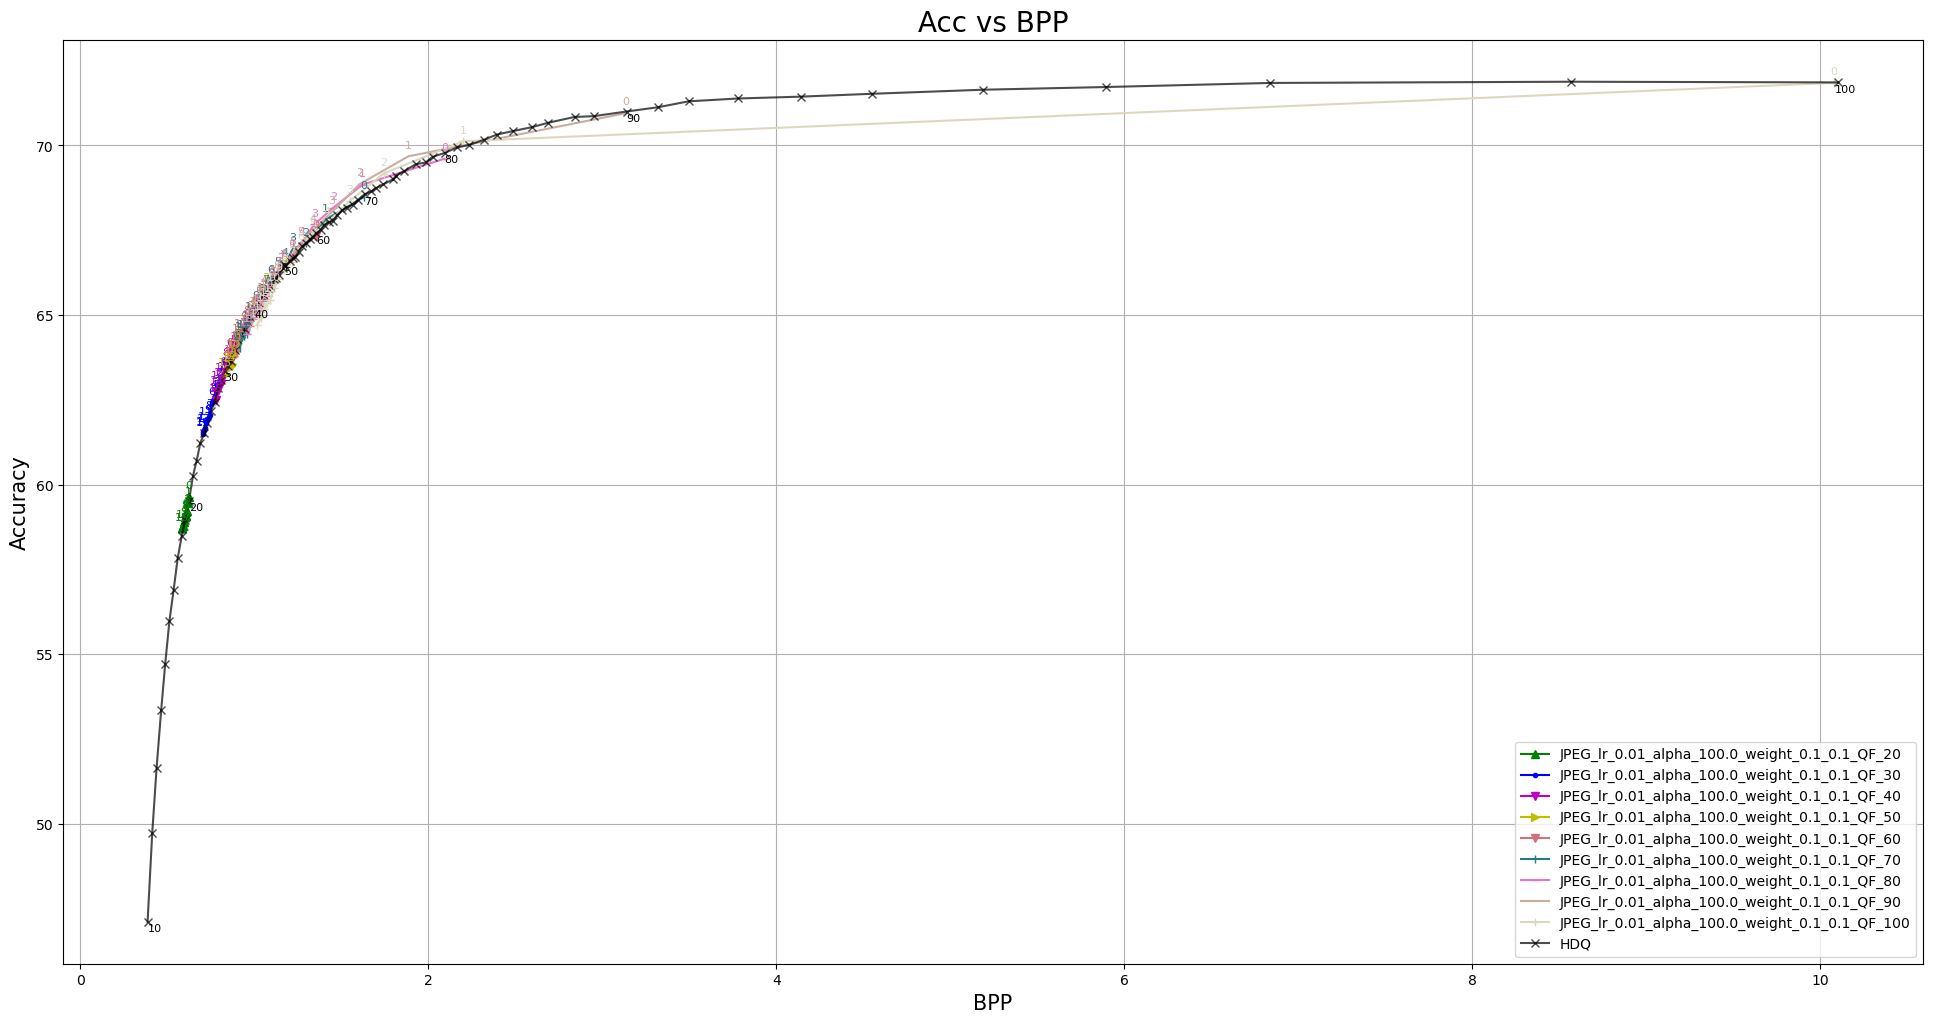

In [33]:
plt.figure(figsize=(24, 12))

# best_epoch_0 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_0), "trial_1/logs.txt"), marker_list[0], file_name_0, color=color_list[0], greedy=True)
best_epoch_1 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_1), "trial_1/logs.txt"), marker_list[1], file_name_1, color=color_list[1], greedy=True)
best_epoch_2 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_2), "trial_1/logs.txt"), marker_list[2], file_name_2, color=color_list[2], greedy=True)
best_epoch_3 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_3), "trial_1/logs.txt"), marker_list[3], file_name_3, color=color_list[3], greedy=True)
best_epoch_4 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_4), "trial_1/logs.txt"), marker_list[4], file_name_4, color=color_list[4], greedy=True)
best_epoch_5 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_5), "trial_1/logs.txt"), marker_list[5], file_name_5, color=color_list[5], greedy=True)
best_epoch_6 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_6), "trial_1/logs.txt"), marker_list[6], file_name_6, color=color_list[6], greedy=True)
best_epoch_7 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_7), "trial_1/logs.txt"), marker_list[7], file_name_7, color=color_list[7], greedy=True)
best_epoch_8 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_8), "trial_1/logs.txt"), marker_list[8], file_name_8, color=color_list[8], greedy=True)
best_epoch_9 = plot_data_bpp(os.path.join(os.path.join(base_path, file_name_9), "trial_1/logs.txt"), marker_list[9], file_name_9, color=color_list[9], greedy=True)

plot_data_HDQ(base_path, 10, 100)
# plt.axhline(y=55.28, color='black', linestyle='--')
plt.xlabel('BPP', fontsize=15)
plt.ylabel('Accuracy', fontsize=15)
plt.title('Acc vs BPP', fontsize=20)
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# Plot Train and Test acc/loss

weight: 0.1
len of data: 16
weight: 0.1
len of data: 16
weight: 0.1
len of data: 16
weight: 0.1
len of data: 16
weight: 0.1
len of data: 16
weight: 0.1
len of data: 16
weight: 0.1
len of data: 16
weight: 0.1
len of data: 16
weight: 0.1
len of data: 16


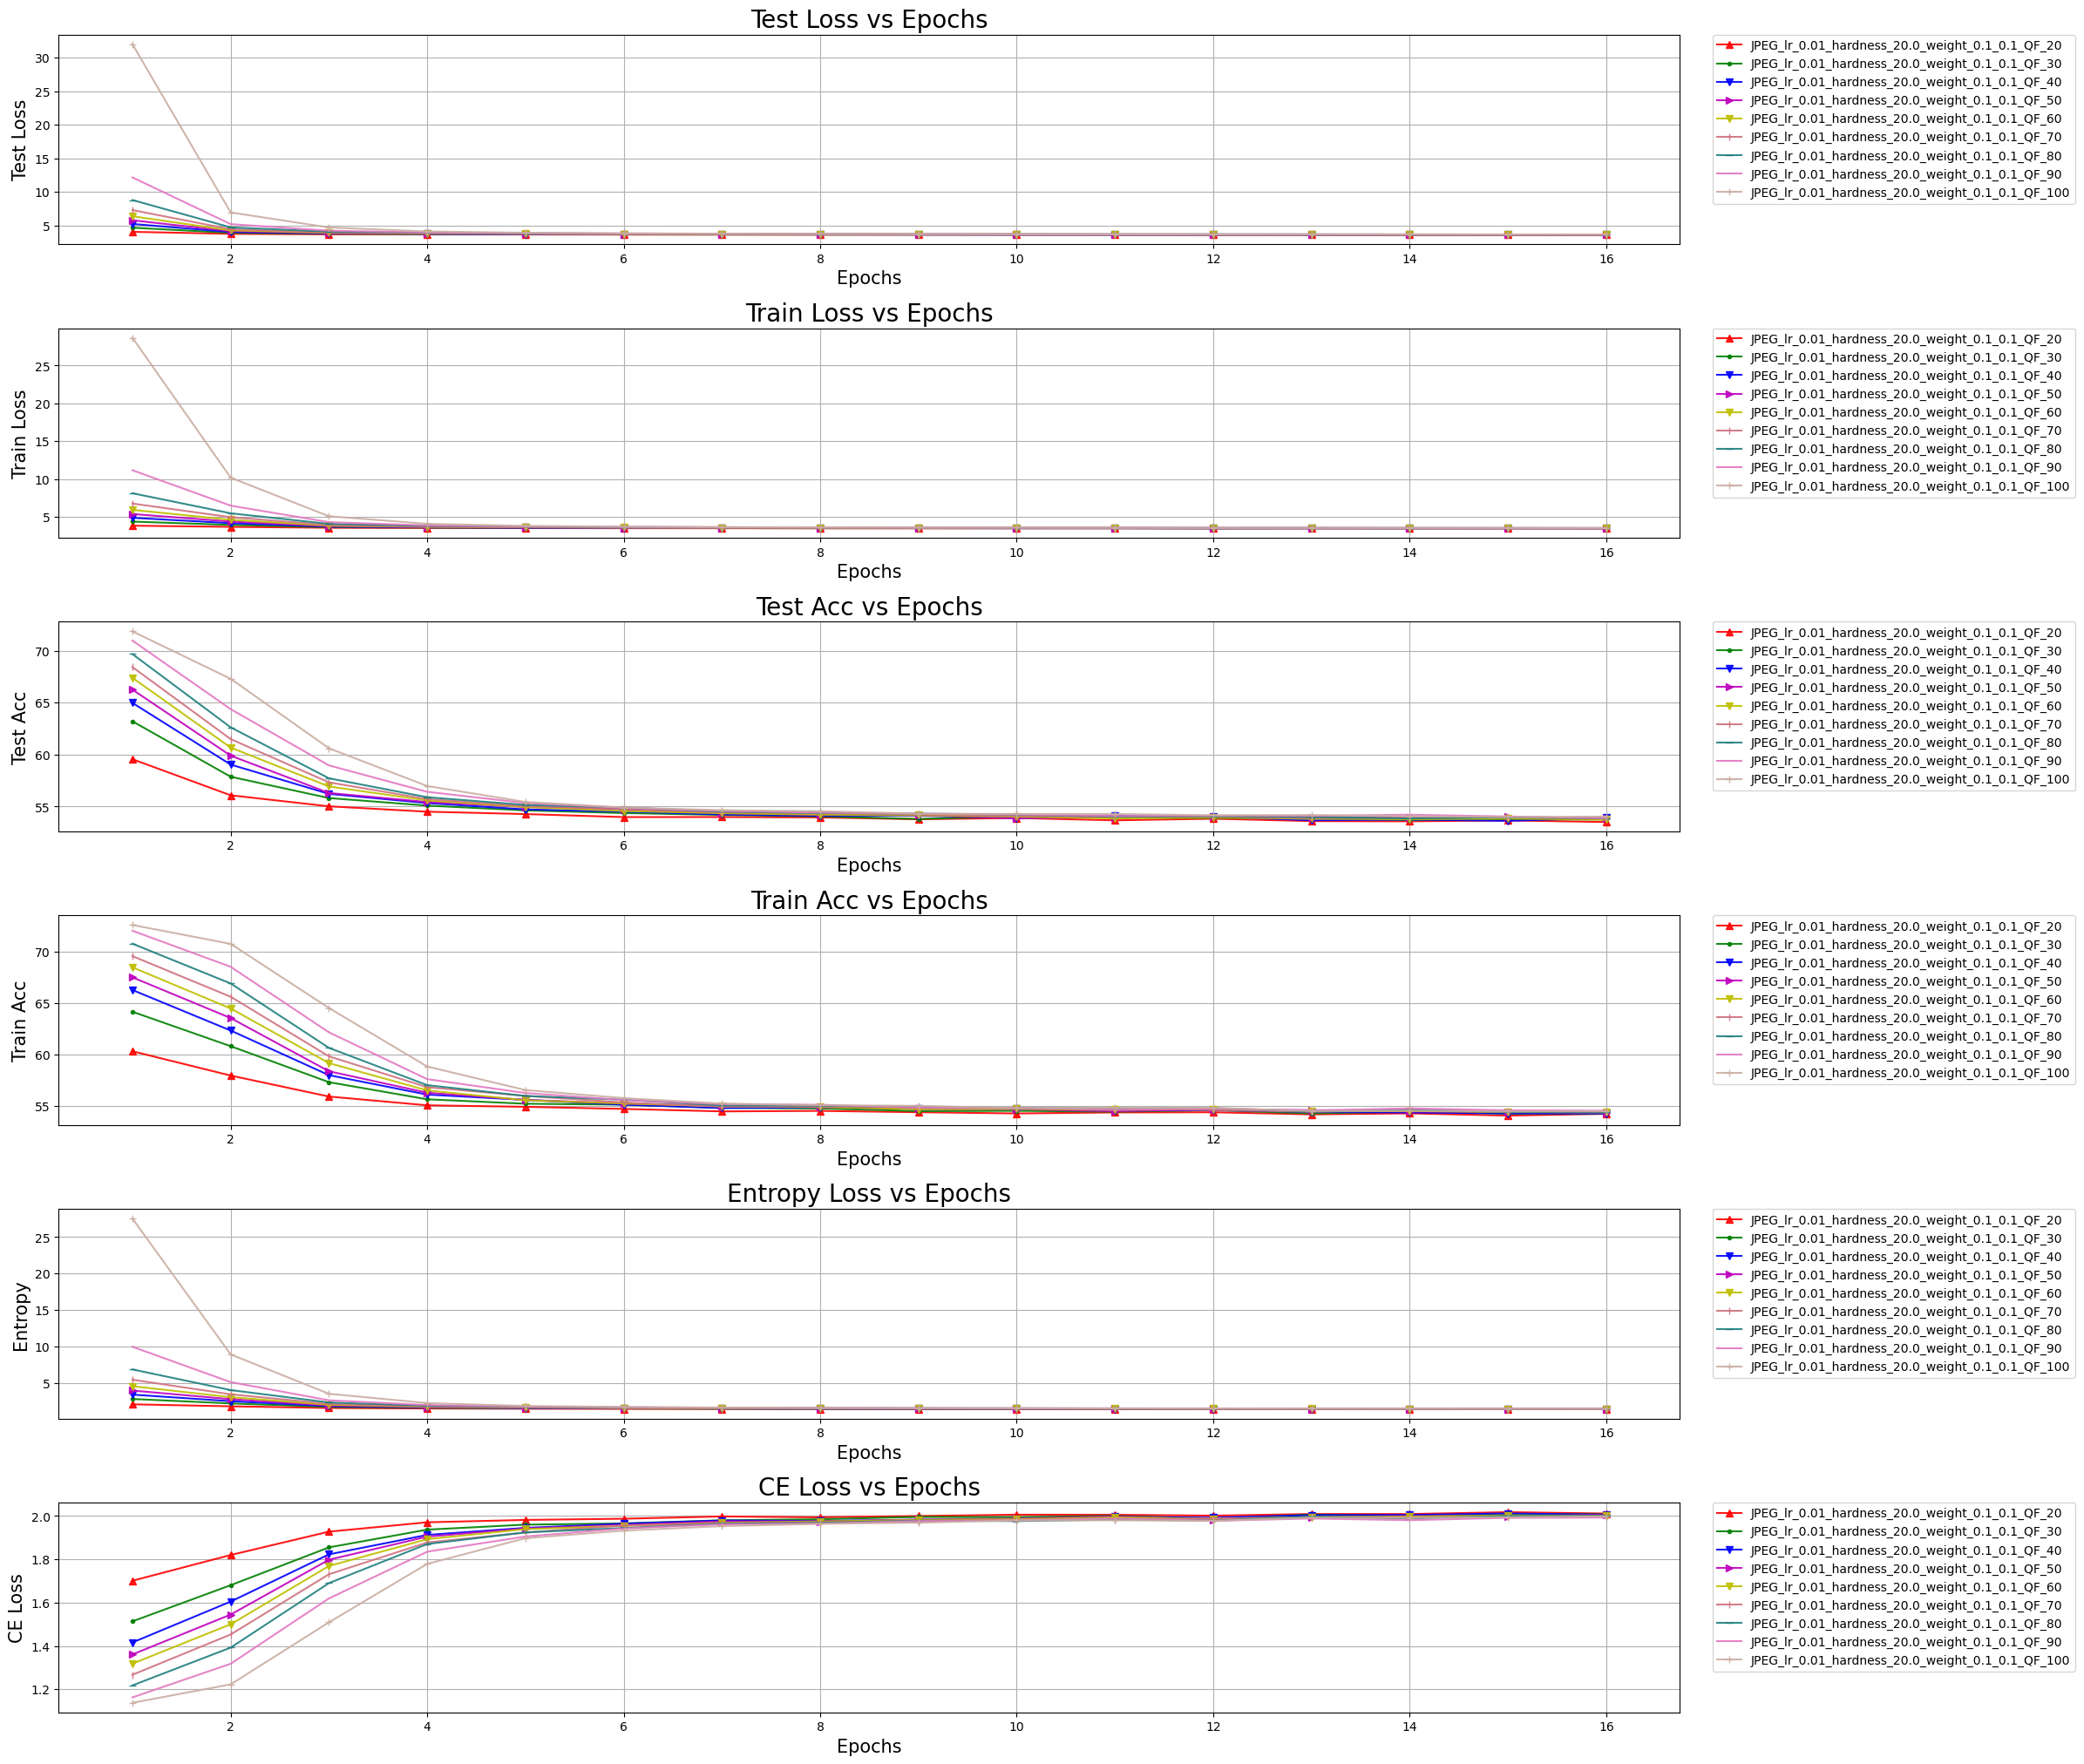

In [12]:
def plot_data_acc_loss(file_path, trial, marker, label, color):
    opt_json_filepath = os.path.join(base_path,label,'trial_{}/opt.json'.format(trial))
    with open(opt_json_filepath, 'r') as f:
        data = json.load(f)
    opt = argparse.Namespace(**data)
    
    weight = opt.weight_lum
    print("weight:", weight)
    data = read_file(file_path)
    print("len of data:", len(data))
    test_acc = [row[2] for row in data]
    train_acc = [row[3] for row in data]
    test_loss = [row[4] for row in data]
    train_loss = [row[5] for row in data]
    entropy = [weight*(row[11] + row[12] + row[13] + row[14]) for row in data]
    CEloss = [(row[5] - weight* (row[11] + row[12] + row[13] + row[14])) for row in data]
    # bpp = [row[6] for row in data]
    
    x_epoch = range(1,len(test_loss)+1)
    ax1.plot(x_epoch, test_loss, marker=marker, label=label, color=color, alpha=0.9)
    ax2.plot(x_epoch, train_loss, marker=marker, label=label, color=color, alpha=0.9)
    ax3.plot(x_epoch, test_acc, marker=marker, label=label, color=color, alpha=0.9)
    ax4.plot(x_epoch, train_acc, marker=marker, label=label, color=color, alpha=0.9)
    ax5.plot(x_epoch, entropy, marker=marker, label=label, color=color, alpha=0.9)
    ax6.plot(x_epoch, CEloss, marker=marker, label=label, color=color, alpha=0.9)


fig, (ax1, ax2, ax3, ax4, ax5, ax6) = plt.subplots(6, 1, figsize=(24, 25))

# plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_0), "trial_1/logs.txt"), 1, marker_list[0], file_name_0, color=color_list[0])
plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_1), "trial_1/logs.txt"), 1, marker_list[1], file_name_1, color=color_list[0])
plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_2), "trial_1/logs.txt"), 1, marker_list[2], file_name_2, color=color_list[1])
plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_3), "trial_1/logs.txt"), 1, marker_list[3], file_name_3, color=color_list[2])
plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_4), "trial_1/logs.txt"), 1, marker_list[4], file_name_4, color=color_list[3])
plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_5), "trial_1/logs.txt"), 1, marker_list[5], file_name_5, color=color_list[4])
plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_6), "trial_1/logs.txt"), 1, marker_list[6], file_name_6, color=color_list[5])
plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_7), "trial_1/logs.txt"), 1, marker_list[7], file_name_7, color=color_list[6])
plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_8), "trial_1/logs.txt"), 1, marker_list[8], file_name_8, color=color_list[7])
plot_data_acc_loss(os.path.join(os.path.join(base_path, file_name_9), "trial_1/logs.txt"), 1, marker_list[9], file_name_9, color=color_list[8])

axes = [ax1, ax2, ax3, ax4, ax5, ax6]
titles = ['Test Loss vs Epochs', 'Train Loss vs Epochs', 'Test Acc vs Epochs', 'Train Acc vs Epochs', 'Entropy Loss vs Epochs', 'CE Loss vs Epochs']
y_labels = ['Test Loss', 'Train Loss', 'Test Acc', 'Train Acc', 'Entropy', 'CE Loss']

for ax, title, y_label in zip(axes, titles, y_labels):
    ax.set_xlabel('Epochs', fontsize=15)
    ax.set_ylabel(y_label, fontsize=15)
    ax.set_title(title, fontsize=20)
    ax.grid(True)
    ax.legend(bbox_to_anchor=(1.02, 1.0), loc=2, borderaxespad=0)

plt.subplots_adjust(hspace=0.4)
plt.show()

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import os


def zigzag(matrix):
    zigzag = np.array([[0, 1, 5, 6, 14, 15, 27, 28],
                        [2, 4, 7, 13, 16, 26, 29, 42],
                        [3, 8, 12, 17, 25, 30, 41, 43],
                        [9, 11, 18, 24, 31, 40, 44, 53],
                        [10, 19, 23, 32, 39, 45, 52, 54],
                        [20, 22, 33, 38, 46, 51, 55, 60],
                        [21, 34, 37, 47, 50, 56, 59, 61],
                        [35, 36, 48, 49, 57, 58, 62, 63]])
    matrix_size = np.shape(matrix)
    vector_size = np.shape(zigzag)
    if matrix_size != vector_size:
        raise ValueError("The matrix size does not match the vector size.")
    vector = np.zeros(matrix_size[0] * matrix_size[1])
    for i in range(matrix_size[0]):
        for j in range(matrix_size[1]):
            index = zigzag[i, j]
            vector[index] = matrix[i, j]
    return vector


def quantizationTable(QF=50, Luminance=True):
    quantizationTableData = np.ones((8, 8), dtype=np.float32)
    if QF == 100:
        return quantizationTableData

    if Luminance == True:
        quantizationTableData = np.array([[16, 11, 10, 16, 24, 40, 51, 61],
                                          [12, 12, 14, 19, 26, 58, 60, 55],
                                          [14, 13, 16, 24, 40, 57, 69, 56],
                                          [14, 17, 22, 29, 51, 87, 80, 62],
                                          [18, 22, 37, 56, 68, 109, 103, 77],
                                          [24, 35, 55, 64, 81, 104, 113, 92],
                                          [49, 64, 78, 87, 103, 121, 120, 101],
                                          [72, 92, 95, 98, 112, 100, 103, 99]])
    else:
        quantizationTableData = np.array([[17, 18, 24, 47, 99, 99, 99, 99],
                                          [18, 21, 26, 66, 99, 99, 99, 99],
                                          [24, 26, 56, 99, 99, 99, 99, 99],
                                          [47, 66, 99, 99, 99, 99, 99, 99],
                                          [99, 99, 99, 99, 99, 99, 99, 99],
                                          [99, 99, 99, 99, 99, 99, 99, 99],
                                          [99, 99, 99, 87, 99, 99, 99, 99],
                                          [99, 99, 99, 99, 99, 99, 99, 99]])
    if QF >= 1:
        if QF < 50:
            S = 5000 / QF
        else:
            S = 200 - 2 * QF

        for i in range(8):
            for j in range(8):
                q = (50 + S * quantizationTableData[i][j]) / 100
                q = np.clip(np.floor(q), 1, 255)
                quantizationTableData[i][j] = q
    return quantizationTableData


def plot_q_table_QF(QF):
    matrix_lum = quantizationTable(QF, Luminance=True)
    matrix_lum = zigzag(matrix_lum).flatten()
    ax1.plot(matrix_lum, label="QF= "+str(QF), alpha=0.5)
    
    matrix_chrom = quantizationTable(QF, Luminance=False)
    matrix_chrom = zigzag(matrix_chrom).flatten()
    ax2.plot(matrix_chrom, label="QF= "+str(QF), alpha=0.5)


def plot_q_table(filepaths, marker, color, label, epoch_choose=-1):
    with open(os.path.join(filepaths, "lum_q_table.txt"), "r") as lum_file:
        lum_lines = lum_file.read()
    lum_tables = lum_lines.split("\n\n")[:-1]
    
    with open(os.path.join(filepaths, "chrom_q_table.txt"), "r") as chrom_file:
        chrom_lines = chrom_file.read()
    chrom_tables = chrom_lines.split("\n\n")[:-1]
    
    if len(lum_tables)==102:
        lum_tables = lum_tables[1:]
        chrom_tables = chrom_tables[1:]
    print("len of q_tables", len(lum_tables))
    
    # plot lum q_table
    for epoch, (lum_table, chrom_table) in enumerate(zip(lum_tables, chrom_tables)): 
        if epoch_choose >= 0: 
            # only print the lun/chrom qtable for this epoch
            if epoch != epoch_choose:
                continue
        elif epoch % 5 != 0: 
            continue
    
        Lum_matrix = np.array([list(map(float, row.split(","))) for row in lum_table.split("\n")])
        Lum_matrix = zigzag(Lum_matrix).flatten()
        Lum_dc = Lum_matrix[0]
        
        chrom_matrix = np.array([list(map(float, row.split(","))) for row in chrom_table.split("\n")])
        chrom_matrix = zigzag(chrom_matrix).flatten()
        chrom_dc = chrom_matrix[0]
        
        if epoch==0:
            ax1.plot(Lum_matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=1, color="k")
            ax2.plot(chrom_matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=1, color="k")
        else:
            ax1.plot(Lum_matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=0.5)
            ax2.plot(chrom_matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=0.5)

    ax1.set_xlabel('Frequency Index', fontsize=20)
    ax1.set_ylabel('Lum Q steps', fontsize=20)
    ax1.set_title('Lum Q steps vs Frequency Index', fontsize=20)
    ax1.grid(True)
    
    ax2.set_xlabel('Frequency Index', fontsize=20)
    ax2.set_ylabel('Chrom Q steps', fontsize=20)
    ax2.set_title('Chrom Q steps vs Frequency Index', fontsize=20)
    ax2.grid(True)
    

def plot_alpha_table(filepaths, marker, color, label, epoch_choose=-1):
    with open(os.path.join(filepaths, "lum_alpha_table.txt"), "r") as lum_file:
        lum_lines = lum_file.read()
    lum_tables = lum_lines.split("\n\n")[:-1]
    
    with open(os.path.join(filepaths, "chrom_alpha_table.txt"), "r") as chrom_file:
        chrom_lines = chrom_file.read()
    chrom_tables = chrom_lines.split("\n\n")[:-1]
    
    if len(lum_tables)==102:
        lum_tables = lum_tables[1:]
        chrom_tables = chrom_tables[1:]
    print("len of q_tables", len(lum_tables))
    
    # plot lum q_table
    for epoch, (lum_table, chrom_table) in enumerate(zip(lum_tables, chrom_tables)): 
        if epoch_choose >= 0: 
            # only print the lun/chrom alpha_table for this epoch
            if epoch != epoch_choose:
                continue
        elif epoch % 5 != 0: 
            # print all alpha_table for epochs
            continue
    
        Lum_matrix = np.array([list(map(float, row.split(","))) for row in lum_table.split("\n")])
        Lum_matrix = zigzag(Lum_matrix).flatten()
        Lum_dc = Lum_matrix[0]
        
        chrom_matrix = np.array([list(map(float, row.split(","))) for row in chrom_table.split("\n")])
        chrom_matrix = zigzag(chrom_matrix).flatten()
        chrom_dc = chrom_matrix[0]
        
        ax1.plot(Lum_matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=0.5)
        ax2.plot(chrom_matrix, marker=marker, label=label+" epoch {}".format(epoch), alpha=0.5)

    ax1.set_xlabel('Frequency Index', fontsize=15)
    ax1.set_ylabel('Lum Alpha steps', fontsize=15)
    ax1.set_title('Lum Alpha steps vs Frequency Index', fontsize=20)
    ax1.grid(True)
    
    ax2.set_xlabel('Frequency Index', fontsize=15)
    ax2.set_ylabel('Chrom Alpha steps', fontsize=15)
    ax2.set_title('Chrom Alpha steps vs Frequency Index', fontsize=20)
    ax2.grid(True)



# Plot Q tables

len of q_tables 16
len of q_tables 16
len of q_tables 16
len of q_tables 16
len of q_tables 16
len of q_tables 16
len of q_tables 16
len of q_tables 16
len of q_tables 16


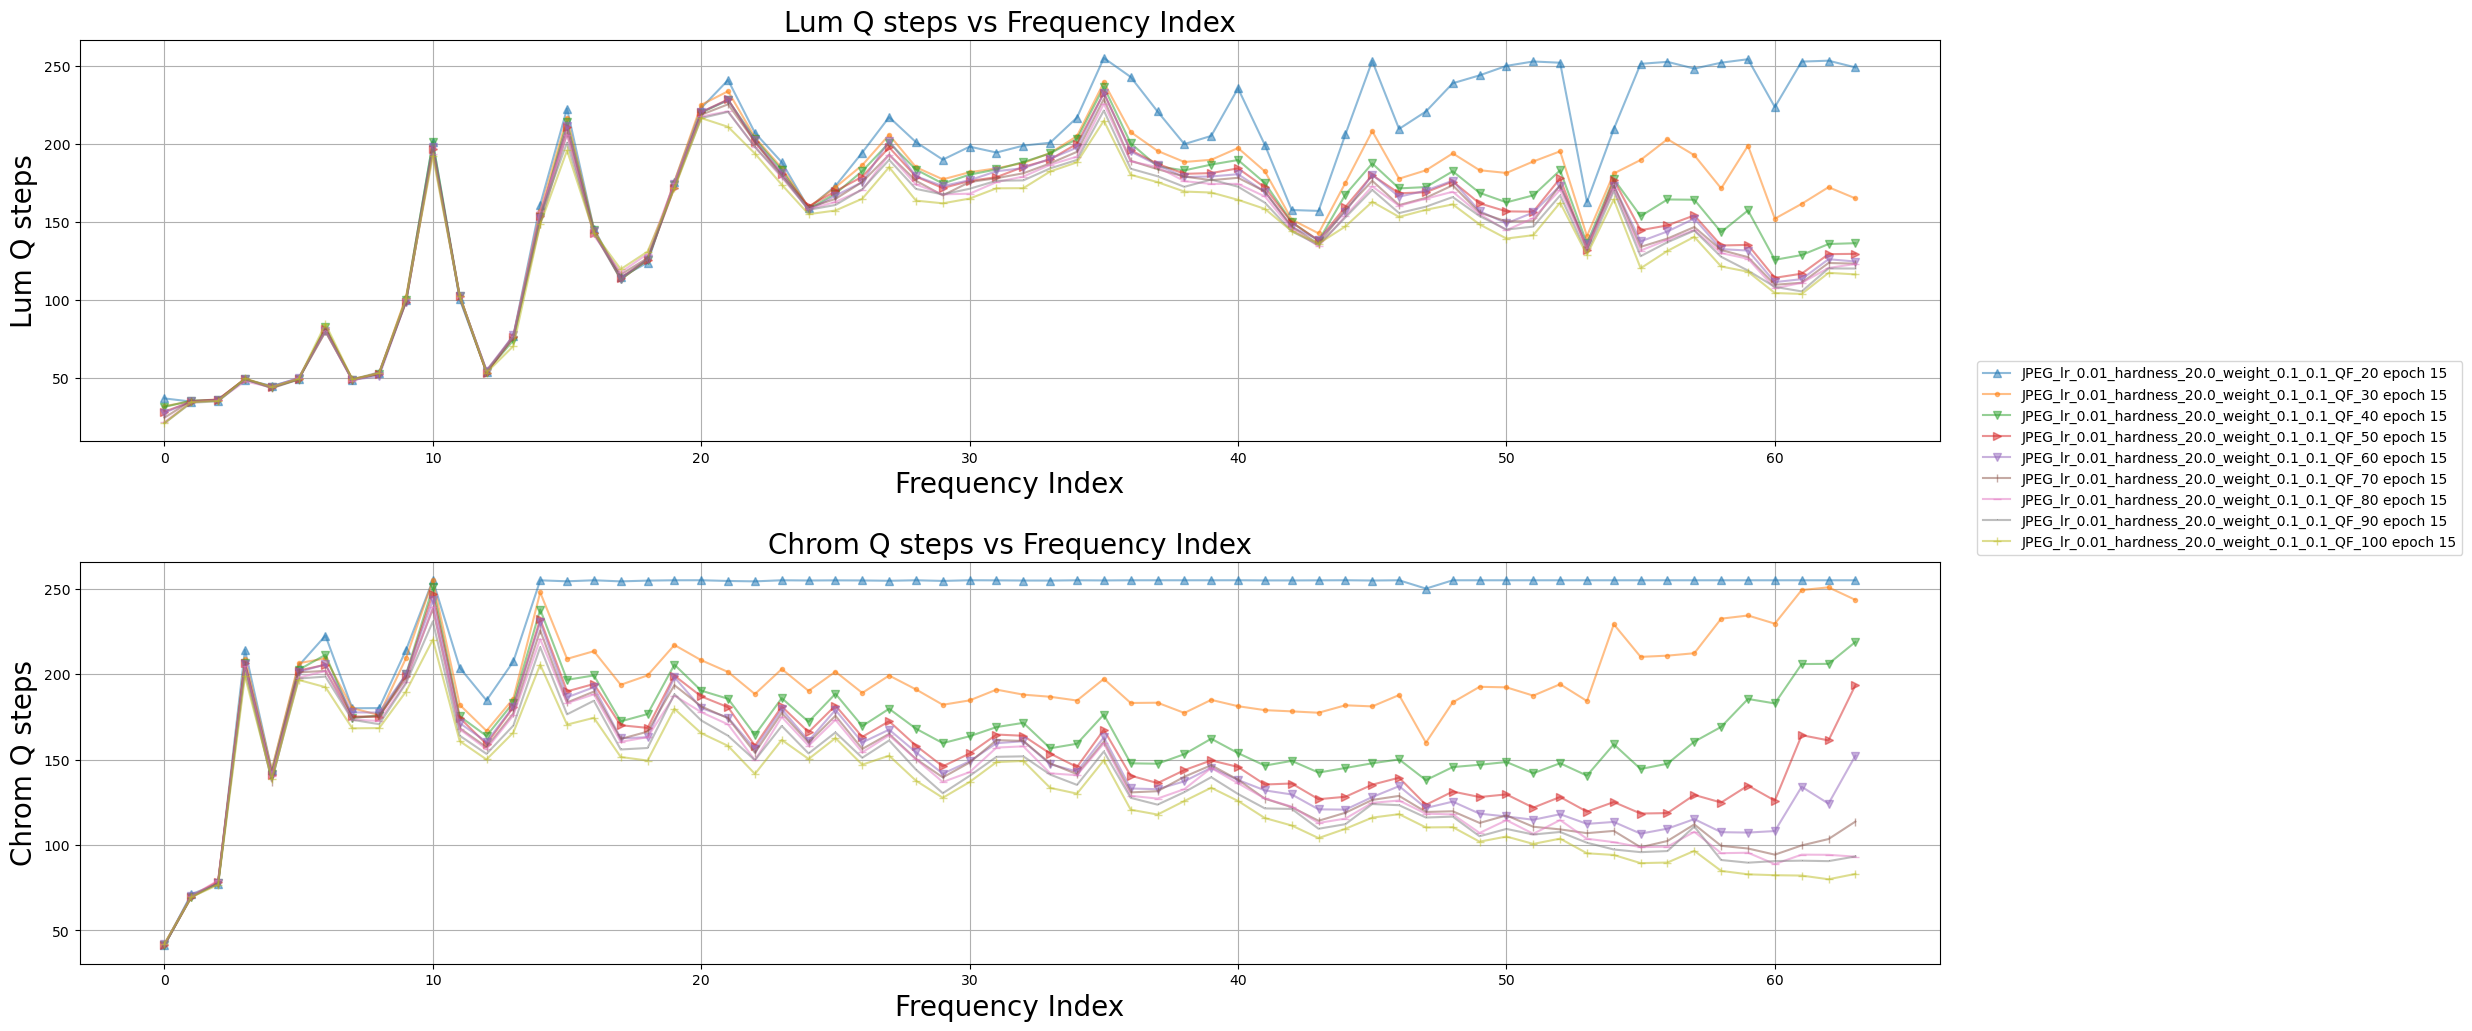

In [21]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(24, 12))

q_path_0 = os.path.join(os.path.join(base_path, file_name_0), "trial_1/Q_tables")
q_path_1 = os.path.join(os.path.join(base_path, file_name_1), "trial_1/Q_tables")
q_path_2 = os.path.join(os.path.join(base_path, file_name_2), "trial_1/Q_tables")
q_path_3 = os.path.join(os.path.join(base_path, file_name_3), "trial_1/Q_tables")
q_path_4 = os.path.join(os.path.join(base_path, file_name_4), "trial_1/Q_tables")
q_path_5 = os.path.join(os.path.join(base_path, file_name_5), "trial_1/Q_tables")
q_path_6 = os.path.join(os.path.join(base_path, file_name_6), "trial_1/Q_tables")
q_path_7 = os.path.join(os.path.join(base_path, file_name_7), "trial_1/Q_tables")
q_path_8 = os.path.join(os.path.join(base_path, file_name_8), "trial_1/Q_tables")
q_path_9 = os.path.join(os.path.join(base_path, file_name_9), "trial_1/Q_tables")

# plot_q_table(q_path_0, marker_list[0], color_list[0], file_name_0)
plot_q_table(q_path_1, marker_list[1], color_list[1], file_name_1,15)
plot_q_table(q_path_2, marker_list[2], color_list[2], file_name_2,15)
plot_q_table(q_path_3, marker_list[3], color_list[3], file_name_3,15)
plot_q_table(q_path_4, marker_list[4], color_list[4], file_name_4,15)
plot_q_table(q_path_5, marker_list[5], color_list[5], file_name_5,15)
plot_q_table(q_path_6, marker_list[6], color_list[6], file_name_6,15)
plot_q_table(q_path_7, marker_list[7], color_list[7], file_name_7,15)
plot_q_table(q_path_8, marker_list[8], color_list[8], file_name_8,15)
plot_q_table(q_path_9, marker_list[9], color_list[9], file_name_9,15)

# plot_q_table_QF(96)

plt.subplots_adjust(hspace=0.3)
plt.legend(bbox_to_anchor=(1.02, 1.5), loc=2, borderaxespad=0)
plt.show()

# Plot Alpha tables

len of q_tables 16


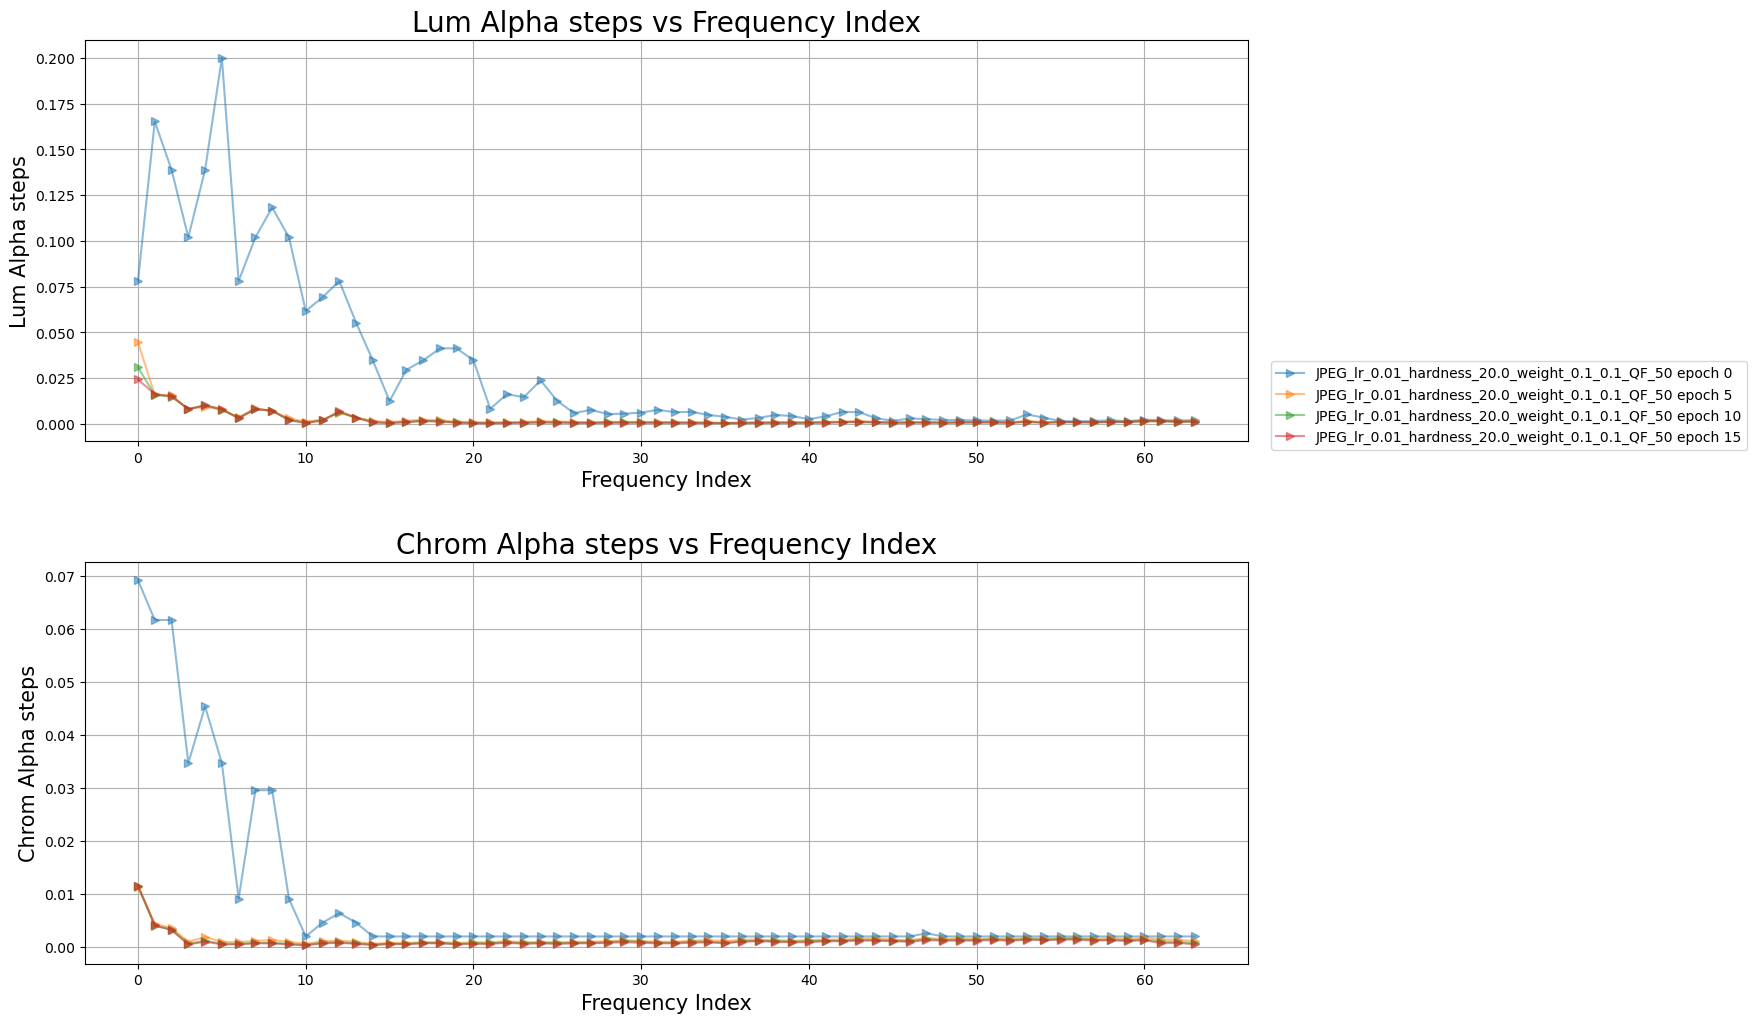

In [19]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 12))

alpha_path_0 = os.path.join(os.path.join(base_path, file_name_0), "trial_1/Alpha_tables")
alpha_path_1 = os.path.join(os.path.join(base_path, file_name_1), "trial_1/Alpha_tables")
alpha_path_2 = os.path.join(os.path.join(base_path, file_name_2), "trial_1/Alpha_tables")
alpha_path_3 = os.path.join(os.path.join(base_path, file_name_3), "trial_1/Alpha_tables")
alpha_path_4 = os.path.join(os.path.join(base_path, file_name_4), "trial_1/Alpha_tables")
alpha_path_5 = os.path.join(os.path.join(base_path, file_name_5), "trial_1/Alpha_tables")
alpha_path_6 = os.path.join(os.path.join(base_path, file_name_6), "trial_1/Alpha_tables")
alpha_path_7 = os.path.join(os.path.join(base_path, file_name_6), "trial_1/Alpha_tables")
alpha_path_8 = os.path.join(os.path.join(base_path, file_name_6), "trial_1/Alpha_tables")
alpha_path_9 = os.path.join(os.path.join(base_path, file_name_6), "trial_1/Alpha_tables")

# plot_alpha_table(alpha_path_0, marker_list[0], color_list[0], file_name_0)
# plot_alpha_table(alpha_path_1, marker_list[1], color_list[1], file_name_1)
# plot_alpha_table(alpha_path_2, marker_list[2], color_list[2], file_name_2)
# plot_alpha_table(alpha_path_3, marker_list[3], color_list[3], file_name_3)
plot_alpha_table(alpha_path_4, marker_list[4], color_list[4], file_name_4)
# plot_alpha_table(alpha_path_5, marker_list[5], color_list[5], file_name_5)
# plot_alpha_table(alpha_path_6, marker_list[6], color_list[6], file_name_6)
# plot_alpha_table(alpha_path_7, marker_list[7], color_list[7], file_name_7)
# plot_alpha_table(alpha_path_8, marker_list[8], color_list[8], file_name_8)
# plot_alpha_table(alpha_path_9, marker_list[9], color_list[9], file_name_9)

plt.subplots_adjust(hspace=0.3)
plt.legend(bbox_to_anchor=(1.02, 1.5), loc=2, borderaxespad=0)
plt.show()

# Plot HDQ baseline

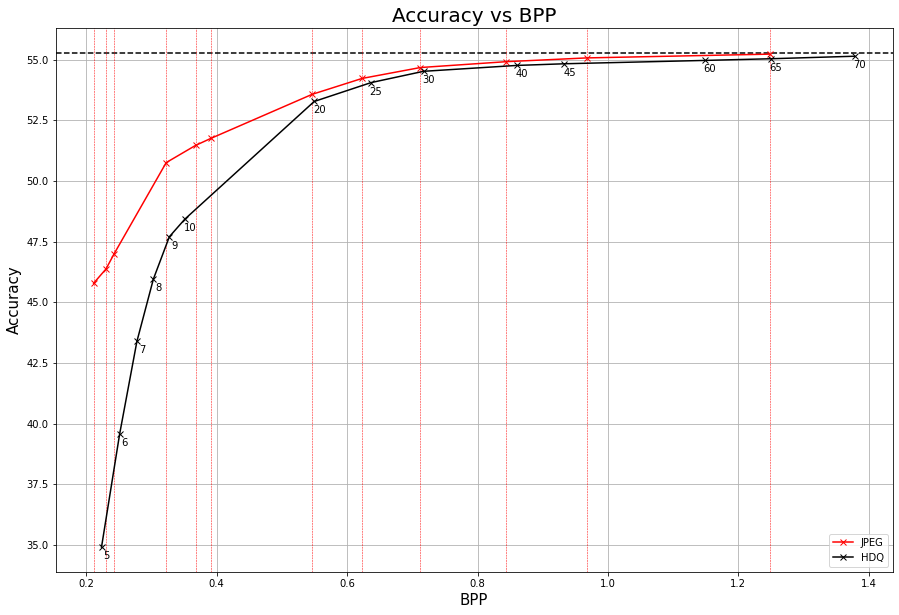

In [55]:
JPEG_x = [1.248896937864914, 0.968056524423821, 0.844145115782546, 0.712328337495558, 0.623033466873948, 
          0.546347268015753, 0.39126013760726, 0.367499542806759, 0.32251122587193, 0.242558152469831, 0.230178814534385, 0.211207192770502]
JPEG_y = [55.22954559326172, 55.074214935302734, 54.918880462646484, 54.67725372314453, 54.228511810302734, 
          53.572662353515625, 51.760440826416016, 51.46703338623047, 50.75940704345703, 46.99689483642578, 46.37556076049805, 45.78874588012695]


plt.figure(figsize=(15, 10))
plt.axhline(y=55.28, color='black', linestyle='--') # baseline

plt.plot(JPEG_x, JPEG_y, marker="x", label="JPEG", color="r")
for x in JPEG_x:
    plt.axvline(x=x, color='red', linestyle='--', linewidth=0.5)
plot_data_HDQ(base_path, 1, 70) # JPGE baseline

plt.xlabel('BPP', fontsize=15)
plt.ylabel('Accuracy', fontsize=15)
plt.title('Accuracy vs BPP', fontsize=20)
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# Calculate Pearson correlation

Pearson correlation coefficient: 0.9960238459466372
P-value: 8.636814268122981e-106


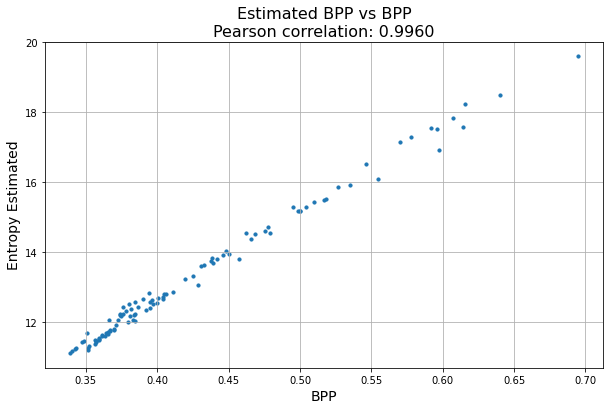

In [64]:
import numpy as np
from scipy.stats import pearsonr

file_name_1 = "JPEG_lr_{}_alpha_{}_weight_{}_{}_QF_{}".format(0.01, 100.0, 0.0001, 0.0001, 10)

Y_data = read_file(os.path.join(os.path.join(base_path, file_name_1), "trial_1/logs.txt"))
CEloss = [(row[7] + row[8] + row[9] + row[10]) for row in Y_data] # entropy
bpp = [(row[6]) for row in Y_data] # test bpp

correlation, p_value = pearsonr(CEloss, bpp)
print(f"Pearson correlation coefficient: {correlation}")
print(f"P-value: {p_value}")

plt.figure(figsize=(10, 6))
plt.scatter(bpp, CEloss, s=10)
plt.title(f'Estimated BPP vs BPP\nPearson correlation: {correlation:.4f}', fontsize=16)
plt.xlabel('BPP', fontsize=14)
plt.ylabel('Entropy Estimated', fontsize=14)
plt.grid(True)
plt.show()

method 1
Pearson correlation coefficient: 0.9779139547429193
P-value: 0.0


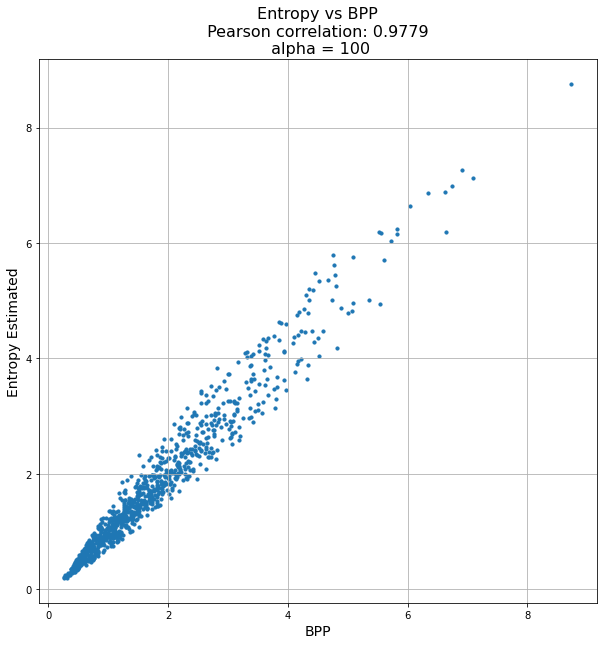

In [92]:
Y_data = read_file("./save/CUB200/resnet18/BPP_Entropy_comparision_1_alpha_100.txt")
# data = data[:500]
CEloss = [(row[1]/22) for row in Y_data] # entropy
bpp = [(row[0]) for row in Y_data] # test bpp

correlation, p_value = pearsonr(CEloss, bpp)
print("method 1")
print(f"Pearson correlation coefficient: {correlation}")
print(f"P-value: {p_value}")

plt.figure(figsize=(10, 10))
plt.scatter(bpp, CEloss, s=10)
plt.title(f'Entropy vs BPP\n Pearson correlation: {correlation:.4f} \n alpha = 100', fontsize=16)
plt.xlabel('BPP', fontsize=14)
plt.ylabel('Entropy Estimated', fontsize=14)
plt.grid(True)
plt.show()

In [8]:
import torch
file_path = './save/imagenet/resnet18/JPEG_lr_0.01_alpha_100.0_weight_0.1_0.1_QF_40/trial_1/Q_tables/q_table_epoch_7.pt'
Y_data = torch.load(file_path)
print(Y_data.shape)

torch.Size([2, 8, 8])


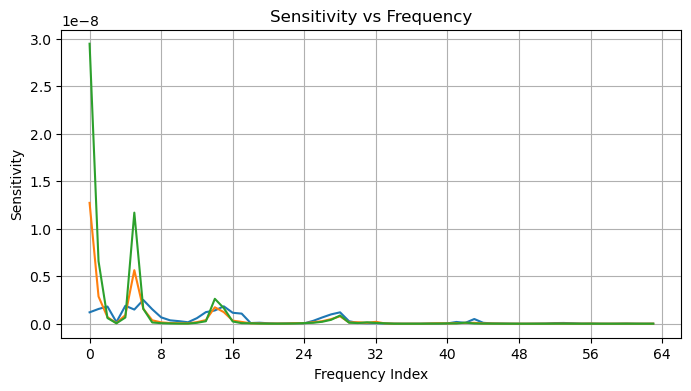

In [16]:
import numpy as np

def visualize_data(data):
    reshaped_data = data.reshape(8, 8)
    flattened_data = zigzag(reshaped_data).flatten()
    plt.plot(flattened_data)


plt.figure(figsize=(8, 4))

Y_data = np.load(os.path.join(base_path, "Y_resnet18.npy"))
Cb_data = np.load(os.path.join(base_path, "Cb_resnet18.npy"))
Cr_data = np.load(os.path.join(base_path, "Cr_resnet18.npy"))

visualize_data(Y_data)
visualize_data(Cb_data)
visualize_data(Cr_data)

plt.title("Sensitivity vs Frequency")
plt.xlabel("Frequency Index")
plt.ylabel("Sensitivity")
plt.xticks(np.arange(0, 65, 8))
plt.grid(True)
plt.show()